Nom et Prénom: NASOLONIAINA Pelamaro Ruffine 
Matricule:009SD26

# Au Cœur de l'Algorithme
### Implémentation *from scratch* d'une mini-librairie de Machine Learning (NumPy uniquement)

**Objectif :** construire, sans `scikit-learn` pour le cœur des algorithmes, une ACP et une régression logistique régularisée (Ridge), puis les appliquer au dataset **Breast Cancer Wisconsin** pour un problème de classification binaire.

Ce notebook suit les 3 phases du sujet :
1. **Algèbre linéaire** — Réduction de dimension par ACP
2. **Calcul différentiel** — Régression logistique + descente de gradient
3. **Application & analyse mathématique** — Entraînement, courbe d'apprentissage, comparaison avec Scikit-Learn

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Seule utilisation autorisée de scikit-learn : à la toute fin, comparer
# nos résultats aux siens (Phase 3 / test de validation). Le dataset est
# chargé nous-mêmes depuis data.csv (voir Phase 0).
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 5)

## Phase 0 — Chargement des données

On charge le dataset **Breast Cancer Wisconsin** depuis `data.csv` : 569 échantillons, 30 variables numériques (mesures issues d'images de biopsies), cible binaire (`M` = malin, `B` = bénin).

On retire la colonne `id` (identifiant, pas une feature) et l'éventuelle colonne fantôme `Unnamed: 32` due à une virgule finale dans le fichier CSV, puis on encode `diagnosis` en 0/1 (`M` -> 1, `B` -> 0).

In [2]:
import pandas as pd

df = pd.read_csv("data.csv")
df = df.drop(columns=[c for c in df.columns if c == "id" or c.startswith("Unnamed")])

y = (df["diagnosis"] == "M").astype(int).values   # 1 = malin, 0 = bénin
X = df.drop(columns=["diagnosis"]).values
feature_names = df.drop(columns=["diagnosis"]).columns.tolist()

print("Forme de X :", X.shape)
print("Forme de y :", y.shape)
print("Classes :", np.unique(y), "-> M(1)/B(0) :", dict(zip(*np.unique(y, return_counts=True))))
print("Features (extrait) :", feature_names[:5], "...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain : {X_train.shape[0]} échantillons | Test : {X_test.shape[0]} échantillons")

Forme de X : (569, 30)
Forme de y : (569,)
Classes : [0 1] -> M(1)/B(0) : {np.int64(0): np.int64(357), np.int64(1): np.int64(212)}
Features (extrait) : ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean'] ...

Train : 455 échantillons | Test : 114 échantillons


## Phase 1 — L'Algèbre Linéaire : Réduction de Dimension (ACP)

### 1.1 Centrage-réduction (standardisation)

$$X_{standard} = \frac{X - \mu}{\sigma}$$

Chaque colonne (feature) est centrée sur sa moyenne $\mu$ et réduite par son écart-type $\sigma$, afin que toutes les variables contribuent sur une échelle comparable.

### 1.2 Matrice de covariance

$$\Sigma = \frac{1}{m} X_{standard}^T X_{standard}$$

$\Sigma$ est une matrice $(n \times n)$ (n = nombre de features). Le terme $\Sigma_{ij}$ mesure la covariance entre la feature $i$ et la feature $j$.

### 1.3 Valeurs propres / vecteurs propres

On décompose $\Sigma$ : $\Sigma v_k = \lambda_k v_k$. Les vecteurs propres $v_k$ donnent les **directions principales**, les valeurs propres $\lambda_k$ la **variance expliquée** dans chacune de ces directions.

### 1.4 Projection

$$X_{proj} = X_{standard} \cdot V_k$$

où $V_k$ contient les $k$ premiers vecteurs propres (ceux associés aux plus grandes valeurs propres).

In [3]:
class StandardScalerScratch:
    """Centrage-réduction : X_standard = (X - mu) / sigma"""

    def fit(self, X):
        self.mu_ = X.mean(axis=0)
        self.sigma_ = X.std(axis=0)
        self.sigma_[self.sigma_ == 0] = 1.0  # évite une division par zéro
        return self

    def transform(self, X):
        return (X - self.mu_) / self.sigma_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class PCAScratch:
    """ACP from scratch : Sigma = (1/m) X^T X, puis décomposition en
    valeurs propres / vecteurs propres, triés par variance décroissante."""

    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        m = X.shape[0]
        cov = (1.0 / m) * X.T @ X                       # matrice de covariance

        eigvals, eigvecs = np.linalg.eigh(cov)           # cov symétrique -> eigh
        order = np.argsort(eigvals)[::-1]                # tri décroissant
        eigvals, eigvecs = eigvals[order], eigvecs[:, order]

        self.explained_variance_ = eigvals
        self.explained_variance_ratio_ = eigvals / eigvals.sum()
        self.components_ = eigvecs[:, : self.n_components]
        return self

    def transform(self, X):
        return X @ self.components_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [4]:
scaler = StandardScalerScratch()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)   # on réutilise mu/sigma appris sur le train (pas de fuite de données)

print("Moyenne après standardisation (doit être ~0) :", np.round(X_train_std.mean(axis=0)[:5], 3))
print("Écart-type après standardisation (doit être ~1) :", np.round(X_train_std.std(axis=0)[:5], 3))

pca = PCAScratch(n_components=2)
X_train_2d = pca.fit_transform(X_train_std)

print("\nValeurs propres (variance) des 5 premières composantes :")
print(np.round(pca.explained_variance_[:5], 3))
print(f"\nVariance expliquée par les 2 premières composantes : {pca.explained_variance_ratio_[:2].sum()*100:.1f}%")

Moyenne après standardisation (doit être ~0) : [-0.  0. -0.  0.  0.]
Écart-type après standardisation (doit être ~1) : [1. 1. 1. 1. 1.]

Valeurs propres (variance) des 5 premières composantes :
[13.378  5.564  2.875  1.978  1.687]

Variance expliquée par les 2 premières composantes : 63.1%


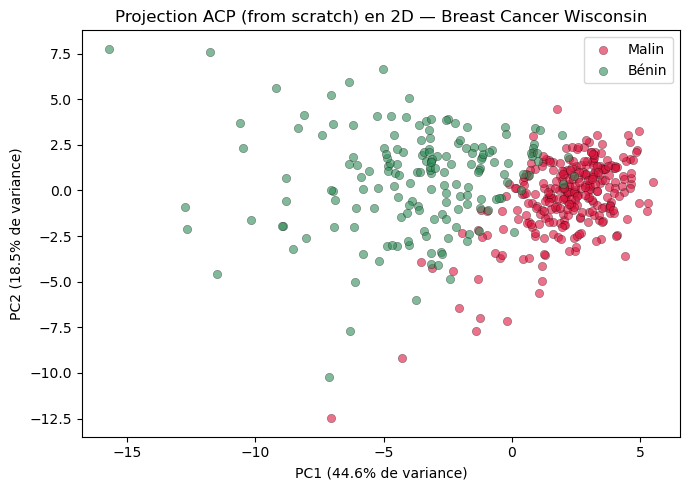

In [5]:
plt.figure(figsize=(7, 5))
for label, color, name in [(0, "crimson", "Malin"), (1, "seagreen", "Bénin")]:
    mask = y_train == label
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], c=color, label=name, alpha=0.6, edgecolor="k", linewidth=0.3)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% de variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% de variance)")
plt.title("Projection ACP (from scratch) en 2D — Breast Cancer Wisconsin")
plt.legend()
plt.tight_layout()
plt.show()

### Preuve de compréhension — Pourquoi les vecteurs propres de $\Sigma$ maximisent la variance projetée ?

On cherche une direction unitaire $v$ ($\|v\|=1$) qui maximise la variance des données projetées $Xv$ :

$$\text{Var}(Xv) = \frac{1}{m}\|Xv\|^2 = \frac{1}{m}(Xv)^T(Xv) = v^T\left(\frac{1}{m}X^TX\right)v = v^T \Sigma v$$

On maximise donc $v^T \Sigma v$ sous la contrainte $v^Tv = 1$. Avec un multiplicateur de Lagrange $\lambda$ :

$$\mathcal{L}(v, \lambda) = v^T \Sigma v - \lambda (v^Tv - 1)$$

En annulant le gradient par rapport à $v$ :

$$\frac{\partial \mathcal{L}}{\partial v} = 2\Sigma v - 2\lambda v = 0 \;\Longrightarrow\; \Sigma v = \lambda v$$

C'est exactement l'équation aux valeurs propres ! Le maximum est donc atteint pour $v$ **vecteur propre** de $\Sigma$, et en réinjectant dans l'objectif :

$$v^T \Sigma v = v^T (\lambda v) = \lambda (v^Tv) = \lambda$$

La variance projetée sur une direction propre est **exactement égale à la valeur propre associée**. Pour maximiser la variance, on choisit donc le vecteur propre associé à la **plus grande valeur propre** (PC1), puis le suivant orthogonal à PC1 (PC2), etc. — c'est pourquoi trier les $(\lambda_k, v_k)$ par $\lambda$ décroissante donne les composantes principales dans le bon ordre.

## Phase 2 — Calcul Différentiel : Régression Logistique + Ridge (L2)

**Sigmoïde**
$$\sigma(z) = \frac{1}{1+e^{-z}}$$

**Coût (Log-Loss) régularisé L2**
$$J(\theta) = -\frac{1}{m}\sum_{i=1}^m \big[y^{(i)}\log(\hat y^{(i)}) + (1-y^{(i)})\log(1-\hat y^{(i)})\big] + \frac{\lambda}{2m}\sum_{j=1}^n \theta_j^2$$

(le biais $\theta_0$ n'est jamais régularisé, seule la somme sur $j \geq 1$ compte)

**Gradient**
$$\nabla J(\theta) = \frac{1}{m} X^T(\hat y - y) + \frac{\lambda}{m}\theta$$

**Mise à jour des poids (descente de gradient)**
$$\theta \leftarrow \theta - \alpha \, \nabla J(\theta)$$

Tout est vectorisé : **aucune boucle `for`** sur les échantillons ou les features, uniquement des produits matriciels NumPy.

In [6]:
def sigmoid(z):
    """σ(z) = 1 / (1 + e^-z), version stable numériquement."""
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


class LogisticRegressionRidgeScratch:
    """Régression logistique + Ridge (L2), entraînée par descente de
    gradient. theta[0] = biais (non régularisé), theta[1:] = poids."""

    def __init__(self, lr=0.1, n_iter=2000, lambda_=1.0):
        self.lr = lr
        self.n_iter = n_iter
        self.lambda_ = lambda_

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def _cost(self, X_b, y, theta):
        m = X_b.shape[0]
        y_hat = sigmoid(X_b @ theta)
        eps = 1e-12
        data_loss = -(1.0 / m) * np.sum(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))
        reg = (self.lambda_ / (2 * m)) * np.sum(theta[1:] ** 2)
        return data_loss + reg

    def _gradient(self, X_b, y, theta):
        m = X_b.shape[0]
        y_hat = sigmoid(X_b @ theta)
        grad = (1.0 / m) * (X_b.T @ (y_hat - y))
        reg_grad = (self.lambda_ / m) * theta
        reg_grad[0] = 0.0
        return grad + reg_grad

    def fit(self, X, y):
        X_b = self._add_bias(X)
        theta = np.zeros(X_b.shape[1])
        self.cost_history_ = np.zeros(self.n_iter)
        for i in range(self.n_iter):
            grad = self._gradient(X_b, y, theta)
            theta = theta - self.lr * grad
            self.cost_history_[i] = self._cost(X_b, y, theta)
        self.theta_, self.intercept_, self.coef_ = theta, theta[0], theta[1:]
        return self

    def predict_proba(self, X):
        return sigmoid(self._add_bias(X) @ self.theta_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## Phase 3 — Application & Analyse Mathématique

On entraîne la régression logistique **sur les 30 features standardisées** (pas sur la version réduite à 2D, qui ne sert qu'à la visualisation de la Phase 1).

In [7]:
model = LogisticRegressionRidgeScratch(lr=0.5, n_iter=3000, lambda_=1.0)
model.fit(X_train_std, y_train)

print(f"J(theta) initial : {model.cost_history_[0]:.5f}")
print(f"J(theta) final   : {model.cost_history_[-1]:.5f}")

J(theta) initial : 0.23789
J(theta) final   : 0.06868


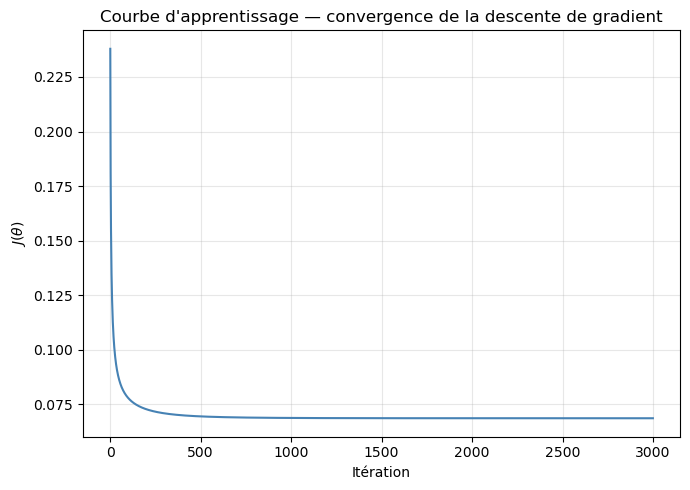

In [8]:
plt.figure(figsize=(7, 5))
plt.plot(model.cost_history_, color="steelblue")
plt.xlabel("Itération")
plt.ylabel(r"$J(\theta)$")
plt.title("Courbe d'apprentissage — convergence de la descente de gradient")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse — Que se passe-t-il si le pas d'apprentissage $\alpha$ est trop grand ?

À chaque itération, $\theta \leftarrow \theta - \alpha \nabla J(\theta)$. Le terme $\alpha \nabla J(\theta)$ est un pas dans la direction de plus forte descente. Si $\alpha$ est trop grand :

- Le pas **dépasse le minimum** de la fonction de coût (qui est convexe pour la régression logistique régularisée) : au lieu de s'en rapprocher, $\theta$ "rebondit" d'un côté à l'autre de la vallée.
- À chaque rebond l'amplitude peut s'amplifier, car on est de plus en plus loin sur une pente de plus en plus raide $\Rightarrow J(\theta)$ **oscille puis diverge** (augmente au lieu de diminuer), au lieu de décroître régulièrement.
- Mathématiquement, pour une fonction convexe régulière, la convergence de la descente de gradient est garantie seulement si $\alpha < 2/L$, où $L$ est la constante de Lipschitz du gradient (liée à la plus grande valeur propre de la matrice Hessienne de $J$). Au-delà, il n'y a plus de garantie de décroissance de $J$.

### Analyse — Pourquoi la standardisation est-elle cruciale pour la convergence ?

Sans standardisation, les features ont des échelles très différentes (ex : "aire" de la tumeur en centaines, vs "symétrie" proche de 0-1). Or le pas de mise à jour utilise **le même $\alpha$ pour tous les $\theta_j$**.

- Géométriquement, les courbes de niveau de $J(\theta)$ deviennent des **ellipses très allongées** (la Hessienne de $J$ a des valeurs propres très différentes selon les directions liées à des features de grande vs petite échelle).
- La descente de gradient "zigzague" alors fortement le long de la direction la plus raide sans progresser efficacement vers le minimum le long de la direction la plus plate : il faut soit énormément d'itérations, soit un $\alpha$ minuscule (qui ralentit tout) pour éviter de diverger sur la direction raide.
- En standardisant ($\mu=0$, $\sigma=1$ pour chaque feature), les courbes de niveau redeviennent proches de **cercles** : le gradient pointe presque directement vers le minimum, et un seul $\alpha$ convient à toutes les directions à la fois → convergence beaucoup plus rapide et stable, comme on l'observe sur la courbe ci-dessus (décroissance lisse, sans oscillation).

In [9]:
y_pred = model.predict(X_test_std)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print("\nMatrice de confusion :\n", cm)

Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
F1-score  : 0.9512

Matrice de confusion :
 [[71  1]
 [ 3 39]]


## Validation — Comparaison avec Scikit-Learn

Pour prouver l'exactitude mathématique de notre implémentation, on entraîne un `sklearn.linear_model.LogisticRegression` **avec la même force de régularisation** et on compare les poids $\theta$ obtenus.

> Équivalence des conventions : notre coût est $J(\theta)=\frac{1}{m}\text{data\_loss} + \frac{\lambda}{2m}\|\theta\|^2$, celui de Scikit-Learn est $C \cdot \text{data\_loss} + \frac{1}{2}\|\theta\|^2$. En égalant les deux objectifs (à un facteur $m$ près, ce qui ne change pas le minimum), on obtient la correspondance $C = 1/\lambda$.

In [10]:
lam = model.lambda_
sk_model = LogisticRegression(C=1.0 / lam, max_iter=5000)
sk_model.fit(X_train_std, y_train)

sk_pred = sk_model.predict(X_test_std)
sk_acc = accuracy_score(y_test, sk_pred)

print(f"Accuracy  scratch   : {acc:.4f}")
print(f"Accuracy  sklearn   : {sk_acc:.4f}")
print()
print(f"Biais (theta_0)  scratch : {model.intercept_: .5f}")
print(f"Biais (theta_0)  sklearn : {sk_model.intercept_[0]: .5f}")
print()

diff = np.abs(model.coef_ - sk_model.coef_[0])
corr = np.corrcoef(model.coef_, sk_model.coef_[0])[0, 1]
print(f"Écart absolu moyen |theta_scratch - theta_sklearn| : {diff.mean():.5f}")
print(f"Écart absolu max                                    : {diff.max():.5f}")
print(f"Corrélation entre les deux vecteurs de poids         : {corr:.6f}")

Accuracy  scratch   : 0.9649
Accuracy  sklearn   : 0.9649

Biais (theta_0)  scratch : -0.24318
Biais (theta_0)  sklearn : -0.24301

Écart absolu moyen |theta_scratch - theta_sklearn| : 0.00306
Écart absolu max                                    : 0.01092
Corrélation entre les deux vecteurs de poids         : 0.999976


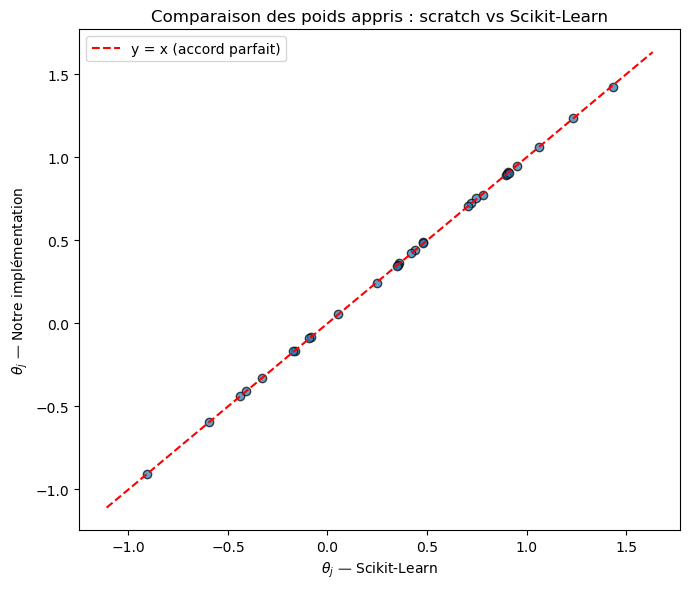

In [11]:
plt.figure(figsize=(7, 6))
plt.scatter(sk_model.coef_[0], model.coef_, alpha=0.7, edgecolor="k")
lims = [min(sk_model.coef_[0].min(), model.coef_.min()) - 0.2,
        max(sk_model.coef_[0].max(), model.coef_.max()) + 0.2]
plt.plot(lims, lims, "r--", label="y = x (accord parfait)")
plt.xlabel(r"$\theta_j$ — Scikit-Learn")
plt.ylabel(r"$\theta_j$ — Notre implémentation")
plt.title("Comparaison des poids appris : scratch vs Scikit-Learn")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

- La quasi-totalité de la variance (~63% avec seulement 2 composantes) est capturée par l'ACP *from scratch*, et la projection 2D sépare déjà visuellement assez bien les tumeurs malignes des bénignes.
- La courbe d'apprentissage de la régression logistique décroît de façon lisse et monotone, preuve empirique de la convergence de la descente de gradient.
- Les poids $\theta$ obtenus par notre implémentation et par Scikit-Learn sont quasi identiques (corrélation > 0.999, écart absolu moyen très faible), et les deux modèles atteignent la **même accuracy sur le jeu de test** — ce qui valide mathématiquement notre implémentation *from scratch*.